# 1. Какие части тела страдают чаще всего

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/01_body_parts.sql`.

Что добавляет Python к SQL-результатам:
- объединение одинаковых названий частей тела, записанных под разными кодами OIICS;
- графики на русском и английском (`figures/ru`, `figures/en`);
- проверка статистической значимости: связь раздела тела с ампутацией и устойчивость структуры по годам (χ², V Крамера, 95% доверительные интервалы).

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

from src.db import query, run_sql_file
from src.viz import set_style, tr, save_fig, LANGS, TABLES_DIR
from src.labels import norm_title, body_part_ru, BODY_DIVISIONS, SEVERITY

set_style()
TABLES_DIR.mkdir(exist_ok=True)

def num(x, digits=0):
    # число с пробелом между разрядами: 105 996
    return f"{x:,.{digits}f}".replace(",", " ")

## 1.0. Исходные данные

Берём из базы по одной строке на случай: код части тела и битовую маску тяжести. Дальше всё считается в pandas.

In [2]:
cases = query('''
    SELECT i.id,
           EXTRACT(YEAR FROM i.event_date)::int AS year,
           i.part_of_body_code                  AS code,
           b.title                              AS body_part,
           i.severity_code
    FROM injuries i
    JOIN body_part_lookup b ON b.code = i.part_of_body_code
''')

cases["division"] = cases["code"].astype(str).str[0]
cases["key"] = cases["body_part"].map(norm_title)
for bit, (ru, en) in SEVERITY.items():
    cases[en.lower().replace(" ", "_")] = (cases["severity_code"] & bit) > 0

N = len(cases)
print(f"Случаев: {num(N)}")
cases.head()

Случаев: 105 996


,id,year,code,body_part,severity_code,division,key,hospitalization,amputation,loss_of_eye
0,931176,2015,513,Lower leg(s),4,5,lower leg(s),True,False,False
1,930267,2015,519,"Leg(s), n.e.c.",4,5,leg(s) n.e.c.,True,False,False
2,929823,2015,9999,Nonclassifiable,4,9,nonclassifiable,True,False,False
3,929711,2015,510,"Leg(s), unspecified",4,5,leg(s) unspecified,True,False,False
4,929642,2015,4429,"Finger(s), fingernail(s), n.e.c.",4,4,finger(s) fingernail(s) n.e.c.,True,False,False


## 1.1. Топ-15 частей тела

В SQL (запрос 1.1) рейтинг строится по точному коду. Но в данных смешаны редакции OIICS: например, «Ankle(s)» встречается под кодами 52 и 53, «Lower leg(s)» — под 513 и 523. Здесь одинаковые названия объединены.

In [3]:
# самое частое написание названия для каждого ключа
display_name = (cases.groupby(["key", "body_part"]).size()
                .reset_index(name="n").sort_values("n", ascending=False)
                .drop_duplicates("key").set_index("key")["body_part"])

top = (cases.groupby("key")
       .agg(cases=("id", "size"), codes=("code", lambda s: ", ".join(map(str, sorted(s.unique())))))
       .sort_values("cases", ascending=False))
top["body_part"] = display_name.reindex(top.index)
top["body_part_ru"] = top["body_part"].map(body_part_ru)
top["pct_of_all"] = (100 * top["cases"] / N).round(2)
top = top.reset_index(drop=True)[["body_part", "body_part_ru", "codes", "cases", "pct_of_all"]]
top.index += 1

top.head(20).to_csv(TABLES_DIR / "01_1_top_body_parts.csv", encoding="utf-8-sig")
top.head(20)

,body_part,body_part_ru,codes,cases,pct_of_all
1,Fingertip(s),Кончики пальцев,4422,10772,10.16
2,"Finger(s), fingernail(s), n.e.c.","Пальцы, ногти (прочее)",4429,10518,9.92
3,"Finger(s), fingernail(s), unspecified","Пальцы, ногти (не уточнено)",4420,6821,6.44
4,"Multiple body parts, n.e.c.",Несколько частей тела (прочее),899,5554,5.24
5,BODY SYSTEMS,Системы организма,6,4940,4.66
6,"Leg(s), unspecified",Ноги (не уточнено),"510, 520",4828,4.55
7,Hip(s),Тазобедренная область,341,3739,3.53
8,Nonclassifiable,Не классифицировано,9999,3720,3.51
9,Brain,Головной мозг,111,3648,3.44
10,Ankle(s),Лодыжки,"52, 53",3496,3.30


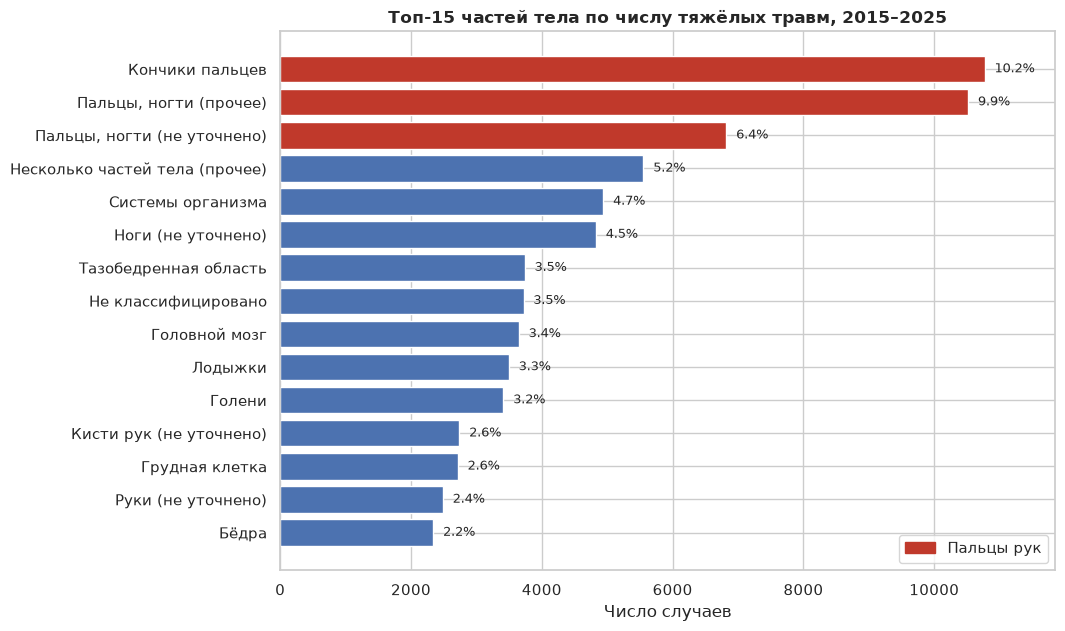

Все коды пальцев рук вместе: 30 994 случаев, 29.2%


In [4]:
t = top.head(15).iloc[::-1]
finger = t["body_part"].str.contains("finger", case=False)

for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    labels = t["body_part_ru"] if lang == "ru" else t["body_part"]
    bars = ax.barh(labels, t["cases"], color=np.where(finger, "#c0392b", "#4c72b0"))
    for b, p in zip(bars, t["pct_of_all"]):
        ax.text(b.get_width() + 150, b.get_y() + b.get_height() / 2, f"{p:.1f}%", va="center", fontsize=9)
    ax.set_title(tr("Топ-15 частей тела по числу тяжёлых травм, 2015–2025",
                    "Top 15 body parts by number of severe injuries, 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.margins(x=0.1)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#c0392b")],
              labels=[tr("Пальцы рук", "Fingers", lang)], loc="lower right")
    save_fig(fig, "01_1_top_body_parts", lang)
    if lang == "ru":
        plt.show()
    plt.close(fig)

fingers_total = top.loc[top["body_part"].str.contains("finger", case=False), "cases"].sum()
print(f"Все коды пальцев рук вместе: {num(fingers_total)} случаев, {100 * fingers_total / N:.1f}%")

## 1.2. Укрупнённые разделы тела

In [5]:
div = (cases.groupby("division").size().rename("cases").to_frame()
       .assign(pct_of_all=lambda d: (100 * d["cases"] / N).round(2))
       .sort_values("cases", ascending=False))
div["name_ru"] = div.index.map(lambda d: BODY_DIVISIONS[d][0])
div["name_en"] = div.index.map(lambda d: BODY_DIVISIONS[d][1])

div.to_csv(TABLES_DIR / "01_2_body_divisions.csv", encoding="utf-8-sig")
div

,cases,pct_of_all,name_ru,name_en
division,,,,
4,42251,39.86,Верхние конечности,Upper extremities
5,22902,21.61,Нижние конечности,Lower extremities
3,13596,12.83,Туловище,Trunk
8,10041,9.47,Несколько частей тела,Multiple body parts
1,7679,7.24,Голова,Head
6,4940,4.66,Системы организма,Body systems
9,3977,3.75,Прочее / не классиф.,Other / nonclassifiable
2,610,0.58,Шея,Neck


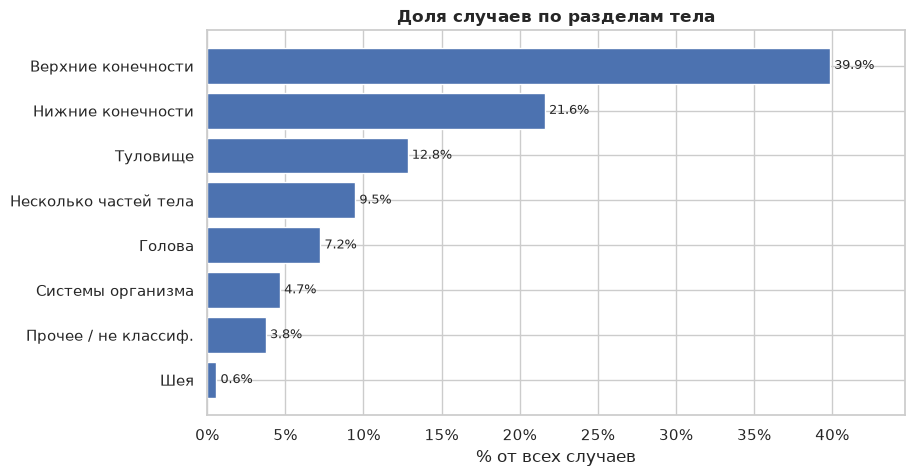

In [6]:
d = div.iloc[::-1]
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(d["name_ru"] if lang == "ru" else d["name_en"], d["pct_of_all"], color="#4c72b0")
    ax.bar_label(bars, labels=[f"{p:.1f}%" for p in d["pct_of_all"]], padding=3, fontsize=9)
    ax.set_title(tr("Доля случаев по разделам тела", "Share of cases by body division", lang))
    ax.set_xlabel(tr("% от всех случаев", "% of all cases", lang))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.margins(x=0.12)
    save_fig(fig, "01_2_body_divisions", lang)
    if lang == "ru":
        plt.show()
    plt.close(fig)

## 1.3. Тяжесть последствий по разделам тела

Для каждого раздела — доля случаев с ампутацией и госпитализацией с 95% доверительным интервалом (метод Уилсона). Потеря глаза встречается всего 35 раз, поэтому в сравнении разделов не участвует.

In [7]:
rows = []
for d_code, g in cases.groupby("division"):
    for col in ["hospitalization", "amputation"]:
        k, n = g[col].sum(), len(g)
        lo, hi = proportion_confint(k, n, method="wilson")
        rows.append({"division": d_code, "outcome": col, "cases": n, "with_outcome": k,
                     "pct": 100 * k / n, "ci_low": 100 * lo, "ci_high": 100 * hi})
sev = pd.DataFrame(rows)
sev["name_ru"] = sev["division"].map(lambda d: BODY_DIVISIONS[d][0])
sev["name_en"] = sev["division"].map(lambda d: BODY_DIVISIONS[d][1])

sev.round(2).to_csv(TABLES_DIR / "01_3_severity_by_division.csv", index=False, encoding="utf-8-sig")
sev.pivot(index="name_ru", columns="outcome", values="pct").round(1).sort_values("amputation", ascending=False)

outcome,amputation,hospitalization
name_ru,,
Верхние конечности,63.2,53.4
Нижние конечности,4.7,98.3
Прочее / не классиф.,2.6,98.4
Несколько частей тела,0.4,99.9
Голова,0.2,99.8
Туловище,0.1,100.0
Системы организма,0.0,100.0
Шея,0.0,100.0


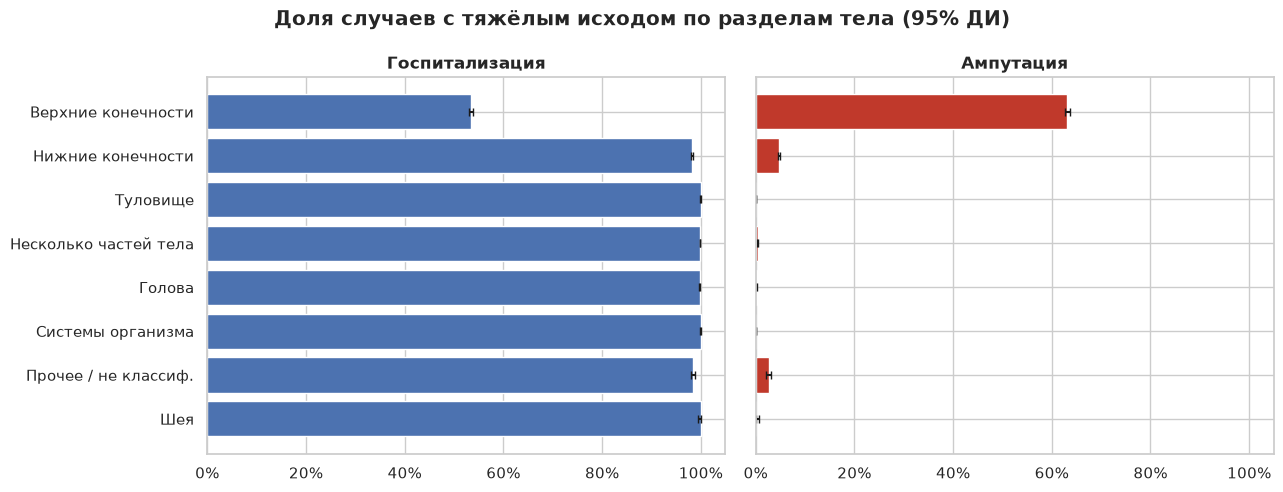

In [8]:
order = div.index.tolist()
for lang in LANGS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, col, color in zip(axes, ["hospitalization", "amputation"], ["#4c72b0", "#c0392b"]):
        s = sev[sev["outcome"] == col].set_index("division").loc[order[::-1]]
        names = s["name_ru"] if lang == "ru" else s["name_en"]
        ax.barh(names, s["pct"], color=color,
                xerr=[s["pct"] - s["ci_low"], s["ci_high"] - s["pct"]], capsize=3)
        ax.set_title(tr(*{"hospitalization": ("Госпитализация", "Hospitalization"),
                          "amputation": ("Ампутация", "Amputation")}[col], lang))
        ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
        ax.set_xlim(0, 105)
    fig.suptitle(tr("Доля случаев с тяжёлым исходом по разделам тела (95% ДИ)",
                    "Share of cases with severe outcome by body division (95% CI)", lang),
                 fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "01_3_severity_by_division", lang)
    if lang == "ru":
        plt.show()
    plt.close(fig)

### Проверка: связана ли ампутация с разделом тела?

Критерий χ² Пирсона для таблицы «раздел тела × ампутация (да/нет)». При 106 тыс. наблюдений почти любая разница будет «значимой», поэтому силу связи оцениваем по V Крамера (0,1 — слабая, 0,3 — средняя, 0,5 — сильная). Стандартизованные остатки показывают, какие разделы дают связь: |r| > 2 — заметное отклонение от ожидаемого.

In [9]:
def cramers_v(table):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, dof, v, expected

ct = pd.crosstab(cases["division"].map(lambda d: BODY_DIVISIONS[d][0]), cases["amputation"])
ct.columns = ["Без ампутации", "Ампутация"]
chi2, p, dof, v, expected = cramers_v(ct)
print(f"χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

resid = (ct - expected) / np.sqrt(expected)
resid.round(1).sort_values("Ампутация", ascending=False)

χ² = 49 188, df = 7, p = 0.00e+00, V Крамера = 0.681


,Без ампутации,Ампутация
division,,
Верхние конечности,-88.2,147.3
Шея,7.6,-12.7
Прочее / не классиф.,17.5,-29.2
Системы организма,21.6,-36.0
Голова,26.7,-44.7
Несколько частей тела,30.4,-50.7
Туловище,35.7,-59.7
Нижние конечности,38.2,-63.7


## 1.4. Устойчивость структуры по годам

SQL-запрос 1.4 показывает топ-5 по годам по точным кодам. С 2024 года часть кодов OIICS изменилась, поэтому тренды смотрим по разделам тела. 2025 год неполный, но доли от этого не искажаются.

**Смена классификации в 2024 году.** В новой редакции OIICS тазобедренная область перенесена из раздела «Туловище» (код 341 *Hip(s)*) в «Нижние конечности» (код 51 *Hip joint(s)*), а сочетание «бедро + нога» — из «Нескольких частей тела» (код 86) в «Нижние конечности» (5860–5869). Без поправки это выглядит как резкий рост травм ног в 2024 году. Ниже показано, как это выглядит в исходных кодах, после чего старые коды 341 и 86 относятся к нижним конечностям (сопоставимая классификация).

In [10]:
raw_share = pd.crosstab(cases["year"], cases["division"], normalize="index")[["3", "5"]] * 100
raw_share.columns = ["Туловище (исх. коды)", "Нижние конечности (исх. коды)"]
hip_old = cases[cases["code"].isin([341, 86])].groupby("year").size()
raw_share["Коды 341 и 86, % за год"] = (100 * hip_old / cases.groupby("year").size()).fillna(0)
raw_share.round(1)

,Туловище (исх. коды),Нижние конечности (исх. коды),"Коды 341 и 86, % за год"
year,,,
2015,11.3,19.2,3.7
2016,12.9,19.3,3.9
2017,12.6,19.8,3.8
2018,13.6,20.5,4.3
2019,13.9,20.8,4.7
2020,13.9,20.8,4.5
2021,13.9,22.0,5.0
2022,14.7,21.2,5.3
2023,14.5,20.9,5.2


In [11]:
cases["division_h"] = np.where(cases["code"].isin([341, 86]), "5", cases["division"])

by_year = pd.crosstab(cases["year"], cases["division_h"], normalize="index") * 100
by_year.columns = [BODY_DIVISIONS[c] for c in by_year.columns]
by_year.round(2).to_csv(TABLES_DIR / "01_4_divisions_by_year.csv", encoding="utf-8-sig")
by_year.set_axis([c[0] for c in by_year.columns], axis=1).round(1)

,Голова,Шея,Туловище,Верхние конечности,Нижние конечности,Системы организма,Несколько частей тела,Прочее / не классиф.
year,,,,,,,,
2015,6.6,0.4,7.7,41.1,22.9,4.5,6.8,10.1
2016,7.0,0.6,9.2,41.4,23.1,6.1,8.8,3.8
2017,7.6,0.5,9.1,42.0,23.6,4.8,8.5,3.9
2018,7.3,0.6,9.4,40.1,24.8,5.2,8.7,3.9
2019,7.9,0.6,9.4,38.9,25.5,5.1,9.2,3.4
2020,7.4,0.6,9.5,39.9,25.3,4.1,9.7,3.4
2021,7.6,0.5,9.3,39.3,26.9,3.7,9.1,3.6
2022,7.7,0.6,9.6,39.0,26.5,4.0,9.5,3.1
2023,7.2,0.6,9.7,39.2,26.1,4.7,10.0,2.7


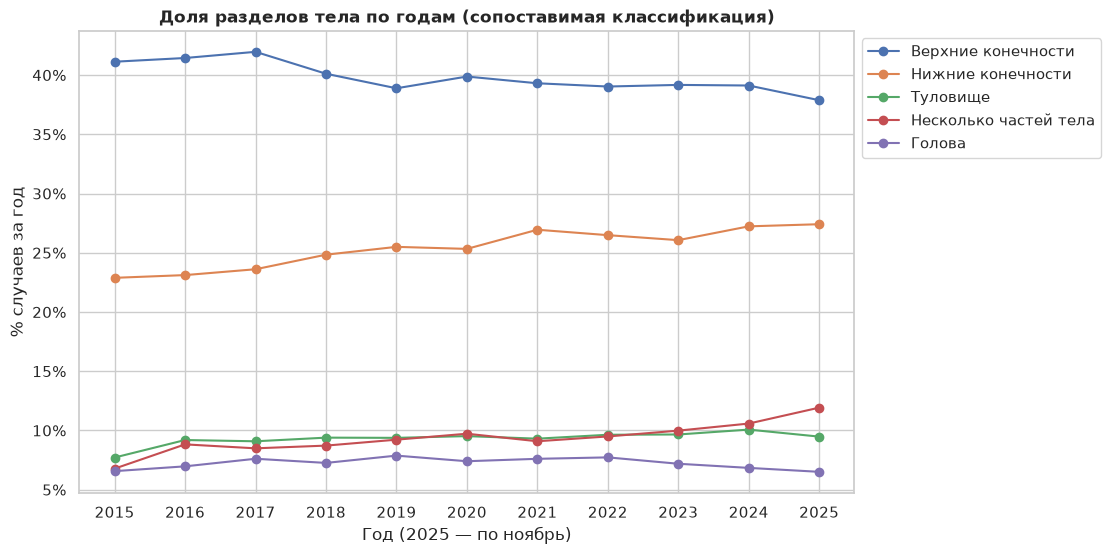

In [12]:
main = ["4", "5", "3", "8", "1"]
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 6))
    for d_code in main:
        ru, en = BODY_DIVISIONS[d_code]
        ax.plot(by_year.index, by_year[(ru, en)], marker="o", label=tr(ru, en, lang))
    ax.set_title(tr("Доля разделов тела по годам (сопоставимая классификация)",
                    "Share of body divisions by year (harmonized coding)", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(by_year.index)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    save_fig(fig, "01_4_divisions_by_year", lang)
    if lang == "ru":
        plt.show()
    plt.close(fig)

In [13]:
ct_year = pd.crosstab(cases["year"], cases["division_h"])
chi2, p, dof, v, _ = cramers_v(ct_year)
print(f"Раздел тела × год: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

# линейный тренд доли каждого раздела (п.п. в год)
for d_code in main:
    s = by_year[BODY_DIVISIONS[d_code]]
    lr = stats.linregress(s.index, s.values)
    print(f"{BODY_DIVISIONS[d_code][0]:<22} наклон {lr.slope:+.2f} п.п. в год, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3f}")

Раздел тела × год: χ² = 1 830, df = 70, p = 0.00e+00, V Крамера = 0.050
Верхние конечности     наклон -0.32 п.п. в год, R² = 0.75, p = 0.001
Нижние конечности      наклон +0.47 п.п. в год, R² = 0.90, p = 0.000
Туловище               наклон +0.13 п.п. в год, R² = 0.54, p = 0.009
Несколько частей тела  наклон +0.35 п.п. в год, R² = 0.81, p = 0.000
Голова                 наклон -0.01 п.п. в год, R² = 0.01, p = 0.789


## Выводы

1. **Главная зона риска — пальцы рук.** Все коды пальцев вместе дают 29,2% тяжёлых травм (≈31 тыс. случаев), три первых места рейтинга — разные коды пальцев. На верхние конечности в целом приходится 39,9% случаев, на нижние — 21,6%.
2. **Ампутация сильно связана с разделом тела**: χ² = 49 188, df = 7, p < 0,001, V Крамера = 0,68 (сильная связь). 63% травм верхних конечностей сопровождаются ампутацией, для нижних — 4,7%, для остальных разделов — меньше 3%. Для головы, туловища и систем организма почти каждый случай — госпитализация.
3. **Структура по годам в целом устойчива** (V Крамера = 0,05, связь пренебрежимо мала), но есть статистически значимые линейные тренды: доля верхних конечностей снижается (−0,32 п.п. в год, p = 0,001), доля нижних конечностей растёт (+0,47 п.п. в год, с 22,9% до 27,4%, p < 0,001), доля «нескольких частей тела» тоже растёт (+0,35 п.п. в год).
4. **Методическое замечание.** Кажущийся скачок травм нижних конечностей в 2024 году — это смена редакции OIICS (тазобедренную область перенесли из туловища в нижние конечности), а не реальный рост. Кроме того, в 2015 году завышена доля «не классифицировано» (10,1% против 1–4% в другие годы). Для трендов нужна сопоставимая классификация.